# Multimodal RAG: ViDoRe V3 Industrial

Loads the `vidore/vidore_v3_industrial` dataset from Hugging Face.

Each config has a single `test` split:

| config | contents |
|---|---|
| `corpus` | one row per page: `corpus_id`, `image`, `doc_id`, `markdown`, `page_number_in_doc` |
| `queries` | `query_id`, `query`, `answer`, `query_types`, ... |
| `qrels` | relevance labels linking `query_id` to `corpus_id` (with `score`, `bounding_boxes`), used as the retrieval ground truth |

In [ ]:
!pip install -q datasets pillow pandas matplotlib torch

In [ ]:
!pip install sentence-transformers

## Load dataset

In [2]:
from datasets import load_dataset

ds_corpus = load_dataset("vidore/vidore_v3_industrial", "corpus")
ds_labels = load_dataset("vidore/vidore_v3_industrial", "qrels")
ds_queries = load_dataset("vidore/vidore_v3_industrial", "queries")

/home/coder/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
# Keep only the English queries.
ds_queries["test"] = ds_queries["test"].filter(lambda lang: lang == "english", input_columns="language")

kept_ids = set(ds_queries["test"]["query_id"])
ds_labels["test"] = ds_labels["test"].filter(lambda qid: qid in kept_ids, input_columns="query_id")
print(f"kept {len(ds_queries['test'])} English queries and {len(ds_labels['test'])} qrels rows")

kept 283 English queries and 1614 qrels rows


In [ ]:
from collections import defaultdict

def build_qrels(qrels) -> dict[int, set[int]]:
    out = defaultdict(set)
    for row in qrels:
        if row["score"] > 0:
            out[row["query_id"]].add(row["corpus_id"])
    return dict(out)

qrels_by_query = build_qrels(ds_labels["test"])  # query_id -> relevant corpus_ids (retrieval ground truth)

print(f"{len(qrels_by_query)} queries with relevance labels")

283 queries with relevance labels


In [ ]:
import numpy as np
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

# Read the column directly: iterating rows would decode every page image just to get the id.
page_ids = ds_corpus["test"]["corpus_id"]

def to_pages(page_scores: np.ndarray, k: int) -> list[int]:
    """Ranked list of the top-k page corpus_ids for one score per page."""
    return [page_ids[i] for i in np.argsort(-page_scores)[:k]]

## Visual retrieval (ColQwen2.5)

Embeds page **images** with [`vidore/colqwen2.5-v0.2`](https://huggingface.co/vidore/colqwen2.5-v0.2), a ColPali-style model built on Qwen2.5-VL (about 3B parameters). Each page becomes a bag of patch vectors (128-dim each) instead of one vector, and each query becomes a bag of token vectors. A page's score is the MaxSim: every query token takes its best-matching patch, and those maxima are summed. It sees layout, tables and figures that text extraction loses, at the cost of far more storage per page than the single-vector dense retriever.

In [6]:
!pip install -q colpali-engine

In [14]:
from pathlib import Path
from colpali_engine.models import ColQwen2_5, ColQwen2_5_Processor
from torch.nn.utils.rnn import pad_sequence
from tqdm.auto import tqdm

# For a smaller, faster model swap in "vidore/colSmol-500M" with ColIdefics3 / ColIdefics3Processor.
VISUAL_MODEL = "vidore/colqwen2.5-v0.2"
# bfloat16 is the dtype in the model card. fp16 can overflow in Qwen2.5-VL (the check at the end catches it).
visual_dtype = torch.bfloat16 if device == "cuda" else torch.float32
# The model and dtype are in the name, so changing either one does not reuse stale vectors.
VISUAL_CACHE = Path(f"page_vecs_{VISUAL_MODEL.split('/')[-1]}_{str(visual_dtype).split('.')[-1]}.pt")

visual_model = ColQwen2_5.from_pretrained(VISUAL_MODEL, torch_dtype=visual_dtype).to(device).eval()
visual_processor = ColQwen2_5_Processor.from_pretrained(VISUAL_MODEL)

PAGE_BATCH = 8    # page images per forward pass; lower it if the GPU runs out of memory
SCORE_BATCH = 64  # pages per padded tensor used for scoring (not text chunks: each page is still one retrieval unit)

corpus_test = ds_corpus["test"]

# Page vectors are the slow step, so they are cached on disk. The model is still loaded above for query encoding.
page_batches = None
if VISUAL_CACHE.exists():
    try:
        page_batches = torch.load(VISUAL_CACHE, map_location=device)
    except Exception as e:  # a save that was interrupted leaves a truncated file
        print(f"Ignoring unreadable cache {VISUAL_CACHE} ({type(e).__name__}), rebuilding")
    if page_batches is None or sum(len(b) for b in page_batches) != len(corpus_test):
        page_batches = None  # unreadable, or built from a different number of pages
    else:
        print(f"Loaded page vectors from {VISUAL_CACHE}")

if page_batches is None:
    page_vecs = []  # one (n_patches, 128) multi-vector per page, in corpus order
    with torch.inference_mode():
        for i in tqdm(range(0, len(corpus_test), PAGE_BATCH)):
            images = corpus_test[i : i + PAGE_BATCH]["image"]
            out = visual_model(**visual_processor.process_images(images).to(device))
            page_vecs.extend(out.cpu())

    # Pages have different patch counts, so they are zero-padded and stacked in groups of SCORE_BATCH.
    page_batches = [pad_sequence(page_vecs[i : i + SCORE_BATCH], batch_first=True).to(device) for i in range(0, len(page_vecs), SCORE_BATCH)]
    del page_vecs
    # Save to a temp file and rename, so an interrupted save cannot leave a truncated cache behind.
    tmp_cache = VISUAL_CACHE.with_suffix(".tmp")
    torch.save([b.cpu() for b in page_batches], tmp_cache)
    tmp_cache.replace(VISUAL_CACHE)
    print(f"Saved page vectors to {VISUAL_CACHE}")

assert all(torch.isfinite(b).all() for b in page_batches), "overflow: set visual_dtype to torch.float32"
print(f"{sum(len(b) for b in page_batches)} pages embedded, {page_batches[0].shape[-1]}-dim vector per patch")

100%|██████████| 656/656 [12:27<00:00,  1.14s/it]


Saved page vectors to page_vecs_colqwen2.5-v0.2_bfloat16.pt
5244 pages embedded, 128-dim vector per patch


In [8]:
def visual_pages(query: str, k: int) -> list[int]:
    with torch.inference_mode():
        q_emb = visual_model(**visual_processor.process_queries([query]).to(device))[0]  # (query_tokens, 128)
        # MaxSim: each query token takes its best-matching patch on the page, and the page score is the
        # sum of those maxima.
        scores = torch.cat([
            torch.einsum("qd,pnd->pqn", q_emb, batch).max(dim=2).values.sum(dim=1)
            for batch in page_batches
        ])
    return to_pages(scores.float().cpu().numpy(), k)

## Multimodal single-vector retrieval (Qwen3-VL-Embedding-2B)

Embeds each page as **one 2048-dim vector** with [`Qwen/Qwen3-VL-Embedding-2B`](https://huggingface.co/Qwen/Qwen3-VL-Embedding-2B) and ranks by cosine similarity to the query vector, like the text dense retriever. Unlike ColQwen2.5 it keeps no per-patch vectors, so storage is tiny and scoring is a single dot product, but fine detail is compressed into one vector.

Two variants are compared:
- **image:** the page image alone. This is the pure visual signal, independent of the OCR text the sparse and text-dense retrievers already use.
- **image + markdown:** the page image and its extracted markdown as one mixed input. It may be more accurate, but it overlaps with the text retrievers and costs more tokens per page.

In [11]:
from sentence_transformers import SentenceTransformer

QWEN_VL_MODEL = "Qwen/Qwen3-VL-Embedding-2B"
# Queries get a task instruction (English works best per the model card), documents are embedded as-is.
QWEN_VL_INSTRUCTION = "Retrieve the document page that answers the question."
QWEN_VL_BATCH = 4  # pages per forward pass; lower it if the GPU runs out of memory

qwen_vl = SentenceTransformer(QWEN_VL_MODEL, device=device)
if device == "cuda":
    qwen_vl.half()


def qwen_vl_page_embeddings(with_markdown: bool) -> np.ndarray:
    """One normalised 2048-dim vector per page, cached on disk. Optionally embeds the page text with the image."""
    variant = "image_markdown" if with_markdown else "image"
    cache = Path(f"page_emb_{QWEN_VL_MODEL.split('/')[-1]}_{variant}.npy")
    if cache.exists():
        emb = np.load(cache)
        if emb.shape[0] == len(corpus_test):
            print(f"Loaded page embeddings from {cache}")
            return emb.astype(np.float32)

    chunks = []
    for i in tqdm(range(0, len(corpus_test), QWEN_VL_BATCH), desc=variant):
        rows = corpus_test[i : i + QWEN_VL_BATCH]
        if with_markdown:
            docs = [{"image": img, "text": md or ""} for img, md in zip(rows["image"], rows["markdown"])]
        else:
            docs = [{"image": img} for img in rows["image"]]
        chunks.append(qwen_vl.encode(docs, normalize_embeddings=True))
    emb = np.concatenate(chunks)
    np.save(cache, emb)
    print(f"Saved page embeddings to {cache}")
    return emb.astype(np.float32)


def make_qwen_vl_retriever(page_embeddings: np.ndarray):
    def retrieve(query: str, k: int) -> list[int]:
        q_emb = qwen_vl.encode(query, prompt=QWEN_VL_INSTRUCTION, normalize_embeddings=True).astype(np.float32)
        # Both sides are normalised, so the dot product is cosine similarity (one score per page).
        return to_pages(page_embeddings @ q_emb, k)
    return retrieve


qwen_vl_image_pages = make_qwen_vl_retriever(qwen_vl_page_embeddings(with_markdown=False))
qwen_vl_image_markdown_pages = make_qwen_vl_retriever(qwen_vl_page_embeddings(with_markdown=True))

image: 100%|██████████| 1311/1311 [11:46<00:00,  1.86it/s]


Saved page embeddings to page_emb_Qwen3-VL-Embedding-2B_image.npy


image_markdown: 100%|██████████| 1311/1311 [12:26<00:00,  1.76it/s]

Saved page embeddings to page_emb_Qwen3-VL-Embedding-2B_image_markdown.npy


## Text retrievers (sparse and dense)

The same sparse (BM25s) and dense (`Qwen/Qwen3-Embedding-0.6B`) retrievers as in `rag_text.ipynb`, repeated here so they can be fused with the visual retrievers. Each page's `markdown` is indexed as one document.

In [15]:
!pip install -q bm25s PyStemmer

In [16]:
import bm25s
import Stemmer
from sentence_transformers import SentenceTransformer

page_texts = [text or "" for text in ds_corpus["test"]["markdown"]]

# Sparse: BM25 over lowercased, stopword-free, stemmed words.
stemmer = Stemmer.Stemmer("english")
bm25 = bm25s.BM25()
bm25.index(bm25s.tokenize(page_texts, stopwords="en", stemmer=stemmer))

def sparse_pages(query: str, k: int) -> list[int]:
    # return_ids=False gives plain string tokens, which get_scores maps through the index vocabulary
    q_tokens = bm25s.tokenize(query, stopwords="en", stemmer=stemmer, return_ids=False, show_progress=False)[0]
    return to_pages(bm25.get_scores(q_tokens), k)

# Dense: Qwen3-Embedding is instruction-aware, so queries get a task prompt and documents are embedded as-is.
EMBED_MODEL = "Qwen/Qwen3-Embedding-0.6B"
QUERY_PROMPT = "Instruct: Given a question about a technical manual, retrieve the page that answers it\nQuery:"
MAX_SEQ_LENGTH = 2048  # whole pages; longer pages are truncated
EMBED_CACHE = Path(f"page_emb_{EMBED_MODEL.split('/')[-1]}_{MAX_SEQ_LENGTH}.npy")

embedder = SentenceTransformer(EMBED_MODEL, device=device, tokenizer_kwargs={"padding_side": "left"})
embedder.max_seq_length = MAX_SEQ_LENGTH
if device == "cuda":
    embedder.half()

# Page embeddings are the slow step, so they are cached on disk (the same file rag_text.ipynb writes).
if EMBED_CACHE.exists() and np.load(EMBED_CACHE, mmap_mode="r").shape[0] == len(page_texts):
    page_emb = np.load(EMBED_CACHE)
    print(f"Loaded page embeddings from {EMBED_CACHE}")
else:
    page_emb = embedder.encode(page_texts, batch_size=4, normalize_embeddings=True, show_progress_bar=True)
    np.save(EMBED_CACHE, page_emb)
    print(f"Saved page embeddings to {EMBED_CACHE}")


def dense_pages(query: str, k: int) -> list[int]:
    q_emb = embedder.encode(query, prompt=QUERY_PROMPT, normalize_embeddings=True)
    # Both sides are normalised, so the dot product is cosine similarity (one score per page).
    return to_pages(np.dot(page_emb, q_emb), k)

DEBUG:bm25s:Building index from IDs objects                          
Batches: 100%|██████████| 1311/1311 [01:07<00:00, 19.37it/s]

Saved page embeddings to page_emb_Qwen3-Embedding-0.6B_2048.npy


## Fusion (sparse + dense + ColQwen2.5, weighted RRF)

Combines rankings with Reciprocal Rank Fusion. Each page scores `sum(weight / (c + rank))` over the retrievers' top-`RRF_POOL` lists it appears in (`c = 60`), so BM25 scores, cosine similarities and MaxSim scores never have to be put on one scale. With equal weights the two text lists outvote the visual one, so the visual weight is raised to see whether that helps. Variants:
- **sparse + dense:** the text-only hybrid from `rag_text.ipynb`.
- **sparse + dense + ColQwen2.5:** the same two lists plus the visual ranking, all with weight 1.
- **sparse + dense + 3x / 5x ColQwen2.5:** the visual list counts for three or five votes.

The weights are fixed in advance rather than tuned, but they are still compared on the same queries they are scored on, so a small lead for one weighting is not evidence that it is better.

In [30]:
from functools import lru_cache

RRF_POOL = 50  # candidates taken from each retriever before fusing
RRF_C = 60     # damping constant from the original RRF paper


def make_rrf(*retrievers, weights=None, pool: int = RRF_POOL, c: int = RRF_C):
    """Fuse the rankings of several retrievers with weighted Reciprocal Rank Fusion."""
    weights = weights or (1,) * len(retrievers)
    assert len(weights) == len(retrievers), "one weight per retriever"

    def fused_pages(query: str, k: int) -> list[int]:
        fused = defaultdict(float)
        for retrieve, weight in zip(retrievers, weights):
            for rank, pid in enumerate(retrieve(query, pool), 1):
                fused[pid] += weight / (c + rank)
        return sorted(fused, key=fused.get, reverse=True)[:k]
    return fused_pages


# Rankings are cached, so a retriever used in several fusions runs once per query.
sparse_cached, dense_cached, visual_cached = (lru_cache(maxsize=None)(fn) for fn in (sparse_pages, dense_pages, visual_pages))

FUSIONS = {
    "hybrid (sparse + dense)": make_rrf(sparse_cached, dense_cached),
    "hybrid (sparse + dense + colqwen2.5)": make_rrf(sparse_cached, dense_cached, visual_cached),
    "hybrid (sparse + dense + 3x colqwen2.5)": make_rrf(sparse_cached, dense_cached, visual_cached, weights=(1, 1, 3)),
    "hybrid (sparse + dense + 5x colqwen2.5)": make_rrf(sparse_cached, dense_cached, visual_cached, weights=(1, 1, 5)),
}

## Benchmark

Page-level retrieval metrics against `qrels` (binary relevance) at several cutoffs `K`: the top 5 (the headline cutoff, also used by the error analysis below), 10 and 20 pages:
- **recall@K:** share of a query's relevant pages found in the top K.
- **nDCG@K:** how well the top K is ordered, with more credit for relevant pages ranked higher (1.0 is a perfect ordering).

Many queries have more than 5 relevant pages, so recall@5 cannot reach 1.0. The cell also prints the highest recall each cutoff could give.

In [31]:
import math
import pandas as pd

K = 5            # headline cutoff, also used by the error analysis below
KS = (5, 10, 20)  # cutoffs reported in the results table
assert K in KS

RETRIEVERS = {
    "sparse (BM25)": sparse_pages,
    "dense (qwen3-emb)": dense_pages,
    "visual (colqwen2.5)": visual_pages,
    "qwen3-vl (image)": qwen_vl_image_pages,
    "qwen3-vl (image + markdown)": qwen_vl_image_markdown_pages,
    **FUSIONS,
}

def evaluate(retrieve_fn, ks=KS) -> pd.DataFrame:
    """recall@k and nDCG@k for every query that has qrels and every k in ks, one row per query."""
    rows = []
    for q in ds_queries["test"]:
        rel = qrels_by_query.get(q["query_id"])
        if not rel:
            continue
        ranking = retrieve_fn(q["query"], max(ks))  # one ranking serves every cutoff
        row = {"query_id": q["query_id"]}
        for k in ks:
            ranked = ranking[:k]
            dcg = sum(1 / math.log2(r + 1) for r, pid in enumerate(ranked, 1) if pid in rel)
            idcg = sum(1 / math.log2(r + 1) for r in range(1, min(len(rel), k) + 1))
            row[f"recall@{k}"] = len(rel & set(ranked)) / len(rel)
            row[f"nDCG@{k}"] = dcg / idcg
        rows.append(row)
    return pd.DataFrame(rows).set_index("query_id")


per_query = {name: evaluate(fn) for name, fn in RETRIEVERS.items()}  # kept for the error analysis below
results = pd.DataFrame({name: df.mean() for name, df in per_query.items()}).T

# The best recall a cutoff allows: a query with 10 relevant pages can score at most 5/10 at K = 5.
ceiling = {k: np.mean([min(k, len(rel)) / len(rel) for rel in qrels_by_query.values()]) for k in KS}
print("highest possible recall:", {f"recall@{k}": round(v, 3) for k, v in ceiling.items()})
results.round(3)

highest possible recall: {'recall@5': np.float64(0.828), 'recall@10': np.float64(0.934), 'recall@20': np.float64(0.992)}


,recall@5,nDCG@5,recall@10,nDCG@10,recall@20,nDCG@20
sparse (BM25),0.426,0.437,0.504,0.451,0.583,0.477
dense (qwen3-emb),0.400,0.420,0.460,0.427,0.549,0.455
visual (colqwen2.5),0.468,0.509,0.552,0.525,0.636,0.551
qwen3-vl (image),0.426,0.434,0.503,0.447,0.628,0.487
qwen3-vl (image + markdown),0.434,0.447,0.533,0.470,0.621,0.498
hybrid (sparse + dense),0.437,0.450,0.525,0.468,0.597,0.492
hybrid (sparse + dense + colqwen2.5),0.470,0.495,0.558,0.513,0.647,0.543
hybrid (sparse + dense + 3x colqwen2.5),0.480,0.504,0.557,0.520,0.638,0.546
hybrid (sparse + dense + 5x colqwen2.5),0.484,0.511,0.570,0.528,0.640,0.551


## Error analysis by query metadata

A query counts as an **error** when none of its relevant pages is in the top `K` (recall@K = 0). The bar charts show the share of errors per `content_type`, `query_types` and `query_format`, with one bar per retriever in `PLOT_RETRIEVERS` (the visual retriever, the text hybrid and the ColQwen2.5 fusion with the highest recall@K). The tables below the charts list every retriever. Categories are ordered worst first, and `n` is the number of queries in the category. If a column holds several labels per query, the query is counted in each of its categories, so the `n` values can add up to more than the number of queries.

charts show: ['visual (colqwen2.5)', 'hybrid (sparse + dense)', 'hybrid (sparse + dense + 5x colqwen2.5)']


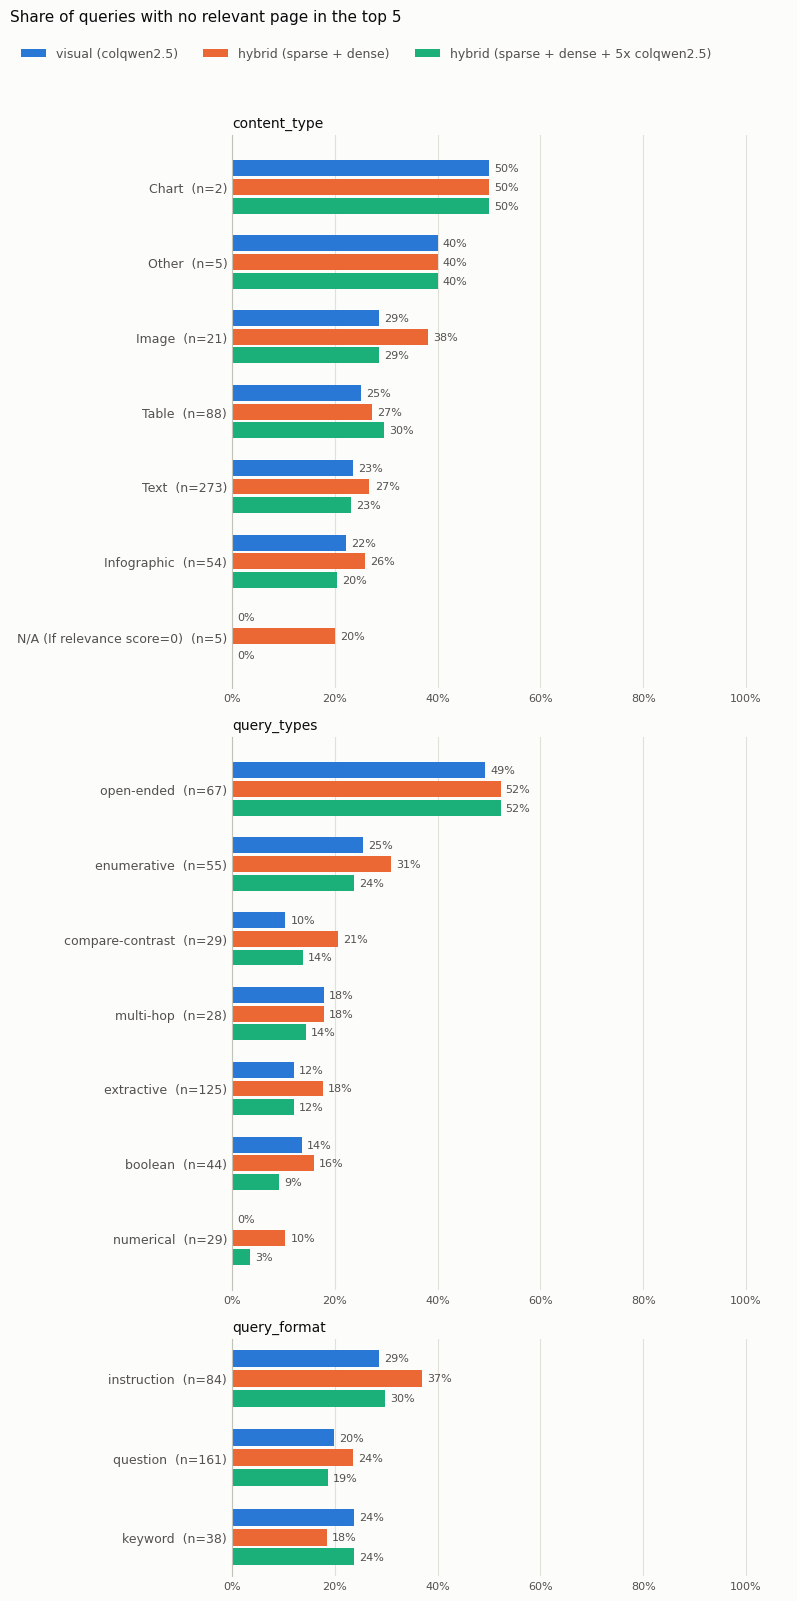

content_type


,sparse (BM25),dense (qwen3-emb),visual (colqwen2.5),qwen3-vl (image),qwen3-vl (image + markdown),hybrid (sparse + dense),hybrid (sparse + dense + colqwen2.5),hybrid (sparse + dense + 3x colqwen2.5),hybrid (sparse + dense + 5x colqwen2.5)
Chart (n=2),1.000,1.000,0.500,0.500,0.500,0.500,0.500,0.500,0.500
Other (n=5),0.200,0.400,0.400,0.800,0.400,0.400,0.400,0.400,0.400
Image (n=21),0.476,0.286,0.286,0.333,0.429,0.381,0.429,0.333,0.286
Table (n=88),0.375,0.307,0.250,0.295,0.273,0.273,0.273,0.284,0.295
Text (n=273),0.330,0.300,0.234,0.315,0.304,0.267,0.245,0.245,0.231
Infographic (n=54),0.407,0.241,0.222,0.315,0.278,0.259,0.259,0.204,0.204
N/A (If relevance score=0) (n=5),0.200,0.600,0.000,0.600,0.600,0.200,0.000,0.000,0.000


query_types


,sparse (BM25),dense (qwen3-emb),visual (colqwen2.5),qwen3-vl (image),qwen3-vl (image + markdown),hybrid (sparse + dense),hybrid (sparse + dense + colqwen2.5),hybrid (sparse + dense + 3x colqwen2.5),hybrid (sparse + dense + 5x colqwen2.5)
open-ended (n=67),0.687,0.493,0.493,0.433,0.493,0.522,0.507,0.537,0.522
enumerative (n=55),0.345,0.255,0.255,0.436,0.291,0.309,0.327,0.255,0.236
compare-contrast (n=29),0.241,0.207,0.103,0.345,0.379,0.207,0.172,0.172,0.138
multi-hop (n=28),0.214,0.250,0.179,0.250,0.214,0.179,0.179,0.143,0.143
extractive (n=125),0.192,0.232,0.120,0.264,0.184,0.176,0.144,0.128,0.120
boolean (n=44),0.227,0.250,0.136,0.182,0.250,0.159,0.136,0.114,0.091
numerical (n=29),0.069,0.103,0.000,0.138,0.069,0.103,0.034,0.034,0.034


query_format


,sparse (BM25),dense (qwen3-emb),visual (colqwen2.5),qwen3-vl (image),qwen3-vl (image + markdown),hybrid (sparse + dense),hybrid (sparse + dense + colqwen2.5),hybrid (sparse + dense + 3x colqwen2.5),hybrid (sparse + dense + 5x colqwen2.5)
instruction (n=84),0.417,0.369,0.286,0.417,0.417,0.369,0.345,0.333,0.298
question (n=161),0.286,0.304,0.199,0.261,0.248,0.236,0.205,0.199,0.186
keyword (n=38),0.289,0.132,0.237,0.263,0.237,0.184,0.184,0.211,0.237


In [32]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

DIMENSIONS = ["content_type", "query_types", "query_format"]
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e1e0d9"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua: one per retriever (at most 3)
# The charts compare the visual retriever with the text hybrid and with the best fusion that adds it.
best_fusion = results.loc[[name for name in FUSIONS if "colqwen" in name], f"recall@{K}"].idxmax()
PLOT_RETRIEVERS = ["visual (colqwen2.5)", "hybrid (sparse + dense)", best_fusion]
print("charts show:", PLOT_RETRIEVERS)

queries_meta = ds_queries["test"].select_columns(["query_id", *DIMENSIONS]).to_pandas().set_index("query_id")

# A query is an error when none of its relevant pages is in the top K.
miss = pd.DataFrame({name: df[f"recall@{K}"] == 0 for name, df in per_query.items()}).astype(float)


def as_labels(value) -> list[str]:
    """Metadata can be a single label or a list of labels (a query can have several types)."""
    if value is None:
        return ["unknown"]
    if isinstance(value, (list, tuple, np.ndarray)):
        return [str(v) for v in value] or ["unknown"]
    return [str(value)]


def miss_rate_by(column: str) -> pd.DataFrame:
    """Miss rate per category (rows) and retriever (columns), worst category first."""
    labels = queries_meta.loc[miss.index, column].map(as_labels).explode().rename("category")
    rates = miss.join(labels).groupby("category").mean()
    counts = labels.value_counts()
    rates.index = [f"{c}  (n={counts[c]})" for c in rates.index]
    return rates.loc[rates.mean(axis=1).sort_values(ascending=False).index]


tables = {col: miss_rate_by(col) for col in DIMENSIONS}
plot_tables = {col: t[PLOT_RETRIEVERS] for col, t in tables.items()}

BAR_H = 0.25  # one bar; three bars (one per retriever) make a category group
total_rows = sum(len(t) for t in tables.values())
fig_h = 1.6 + 0.85 * total_rows
fig, axes = plt.subplots(
    len(DIMENSIONS), 1,
    figsize=(8, fig_h),
    gridspec_kw={"height_ratios": [len(t) for t in tables.values()]},
    facecolor=SURFACE,
)
for ax, (col, rates) in zip(axes, plot_tables.items()):
    ax.set_facecolor(SURFACE)
    y = np.arange(len(rates))
    for j, name in enumerate(rates.columns):
        offset = (j - (len(rates.columns) - 1) / 2) * BAR_H
        ax.barh(y + offset, rates[name], height=BAR_H * 0.85, color=SERIES_COLORS[j], label=name)
        for yy, v in zip(y + offset, rates[name]):
            ax.text(v + 0.01, yy, f"{v:.0%}", va="center", fontsize=8, color=INK_2)
    ax.set_yticks(y, rates.index, color=INK_2, fontsize=9)
    ax.invert_yaxis()  # worst category on top
    ax.set_xlim(0, 1.08)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis="x", colors=INK_2, labelsize=8, length=0)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right", "bottom"):
        ax.spines[side].set_visible(False)
    ax.spines["left"].set_color("#c3c2b7")
    ax.set_title(col, loc="left", color=INK, fontsize=10)

handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(f"Share of queries with no relevant page in the top {K}", color=INK, fontsize=11,
             x=0.01, y=0.995, ha="left")
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 1 - 0.35 / fig_h), ncol=len(labels),
           frameon=False, labelcolor=INK_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.7 / fig_h))
plt.show()

# Table view of the same numbers
for col, rates in tables.items():
    print(col)
    display(rates.round(3))